In [1]:
import matplotlib.pyplot as plt

from softpotato.geometry import PlanarGeometry
from softpotato.techniques import CyclicVoltammetry, simulate
from softpotato.reactions import (
    ElectrochemicalStep,
    FirstOrderReaction,
    Mechanism,
    ButlerVolmer,
    Species,
)

# Constants
D = 1e-9 # m^2/s
cR_bulk = 1 # mol/m^3 (1 mM)
cO_bulk = 0 # mol/m^3
cP_bulk = 0 # mol/m^3
area = 1e-4 # m^2 (1 cm^2)
E0 = 0 # V
n_rxn = 1
kc = 1 # 1/s
k0 = 1 # m/s
alpha = 0.5

# Define CV
cv = CyclicVoltammetry(
    E_start = -0.4,
    E_vertex1 = 0.4,
    E_vertex2 = -0.4,
    scan_rate = 0.1
)

# Species definition
red = Species(
    name = "Red", 
    diffusivity = D, 
    bulk_concentration = cR_bulk, 
    standard_potential = E0, 
    n_electrons = -n_rxn
)

ox = Species(
    name = "Ox",
    diffusivity = D,
    bulk_concentration = cO_bulk,
    standard_potential = E0,
    n_electrons = n_rxn
)

prod = Species(
    name = "Prod",
    diffusivity = D,
    bulk_concentration = cP_bulk,
    n_electrons = 0
)

ec_mech = Mechanism(
    species = [ox, red, prod],
    reactions = [FirstOrderReaction(ox, prod, k=kc)],
    electrochemical_steps = [
        ElectrochemicalStep(
            ox = ox, 
            red = red, 
            kinetics = ButlerVolmer(k0=k0, alpha=alpha, E0=E0, n=n_rxn)
        )
    ]
)

# Set planar geometry
geometry = PlanarGeometry(area)

# Run simulation
# The mechanism is written in the order of the reaction: Ox + e- <-> Red
sim = simulate(
    technique = cv,
    mechanism = ec_mech,
    geometry = geometry
)

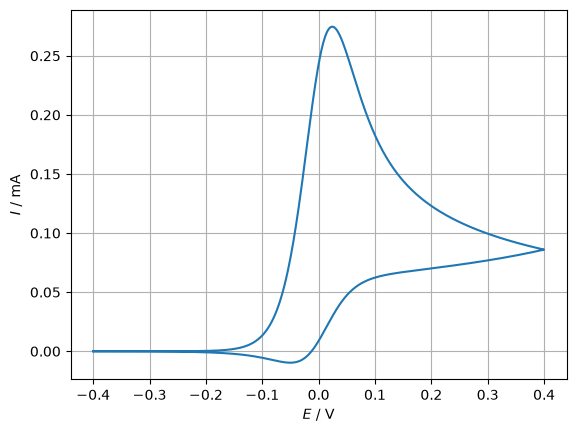

In [2]:
plt.figure()
plt.plot(sim.potential, sim.current*1e3)
plt.xlabel("$E$ / V")
plt.ylabel("$I$ / mA")
plt.grid()
plt.show()

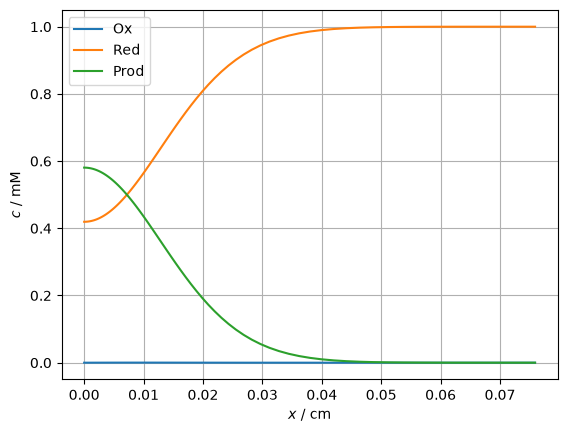

In [3]:
plt.figure()
plt.plot(sim.x*1e2, sim.concentrations["Ox"][-1,:], label="Ox")
plt.plot(sim.x*1e2, sim.concentrations["Red"][-1,:], label="Red")
plt.plot(sim.x*1e2, sim.concentrations["Prod"][-1,:], label="Prod")
plt.xlabel("$x$ / cm")
plt.ylabel("$c$ / mM")
plt.grid()
plt.legend()
plt.show()